# Agentic RAG with Guardrails - Analysis

Fully local, open-source agentic RAG over an enterprise/financial corpus, with access control, NLI-based hallucination guardrails, prompt-injection defense, and a judge-free evaluation harness. This notebook reads the artifacts produced by the `scripts/run_*.py` entry points.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image

OUT = Path('outputs')
eval_r = json.loads((OUT / 'eval.json').read_text())
ablation = json.loads((OUT / 'ablation.json').read_text())
compare = json.loads((OUT / 'compare.json').read_text())
print('loaded eval, ablation, compare artifacts')

loaded eval, ablation, compare artifacts


## 1. Retrieval ablation

Chunking strategy x search strategy, scored on the answerable gold questions. On this small corpus retrieval saturates; `recursive+hybrid` is the chosen default.

In [2]:
pd.DataFrame(ablation).T[['hit@1', 'hit@5', 'mrr', 'ndcg@5']]

,hit@1,hit@5,mrr,ndcg@5
fixed+dense,1.0,1.0,1.0,0.989768
fixed+hybrid,1.0,1.0,1.0,0.993310
recursive+dense,1.0,1.0,1.0,0.993310
recursive+hybrid,1.0,1.0,1.0,1.000000
sentence+dense,1.0,1.0,1.0,0.993310
sentence+hybrid,1.0,1.0,1.0,1.000000


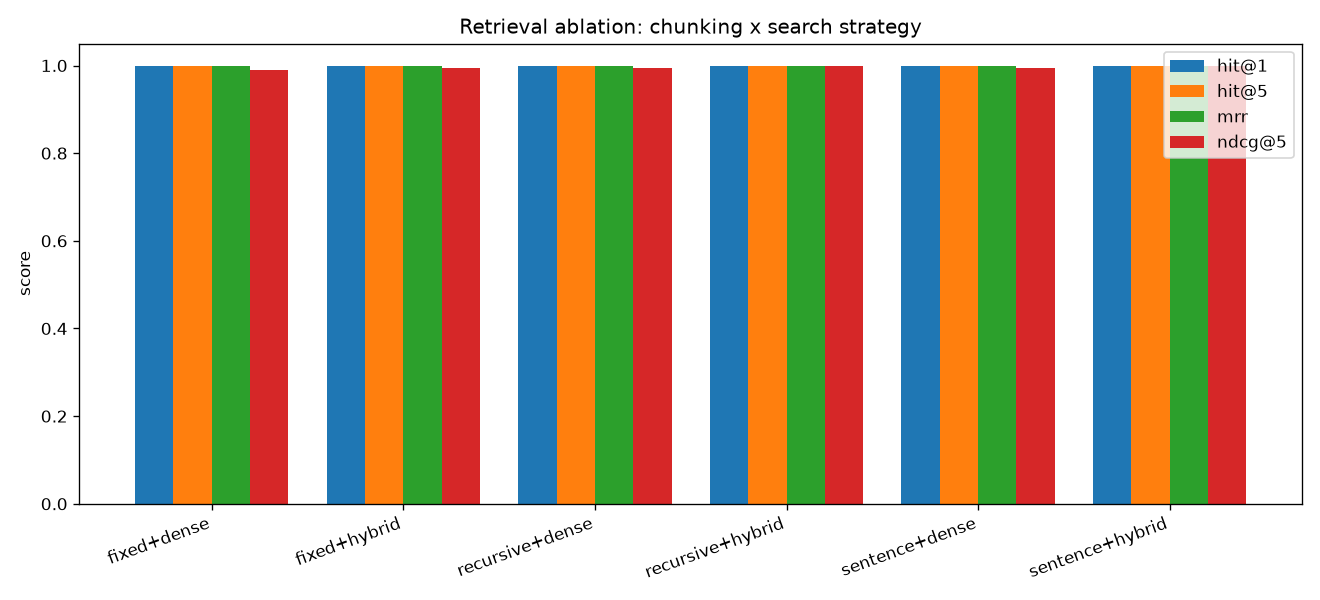

In [3]:
Image(str(OUT / 'figures' / 'ablation.png'))

## 2. Answer quality and safety

Faithfulness is the NLI+embedding groundedness of produced answers; abstention accuracy covers unanswerable and injection cases; ACL retrieval leaks count confidential chunks reaching an under-clearance user (target 0).

In [4]:
summary = {
    'retrieval hit@1': eval_r['retrieval']['hit@1'],
    'retrieval nDCG@5': eval_r['retrieval']['ndcg@5'],
    'abstention accuracy': eval_r['abstention_accuracy'],
    'mean faithfulness': eval_r['answer']['mean_faithfulness'],
    'mean token-F1': round(eval_r['answer']['mean_token_f1'], 3),
    'ACL retrieval leaks': eval_r['acl_denial']['retrieval_leaks'],
}
pd.Series(summary, name='value').to_frame()

,value
retrieval hit@1,1.0000
retrieval nDCG@5,1.0000
abstention accuracy,0.9375
mean faithfulness,1.0000
mean token-F1,0.4200
ACL retrieval leaks,0.0000


## 3. Two-model comparison

Retrieval and guardrails fixed; only the generator swapped. Cost is compute (tokens/sec + VRAM), since both models run locally.

In [5]:
pd.DataFrame(compare['models']).T

,n_answered,mean_token_f1,mean_faithfulness,abstention_accuracy,median_latency_s,mean_tokens_per_s,peak_vram_gb
qwen2.5-1.5b-fp16,11.0,0.4199,1.0,0.9375,1.912,9.3,3.35
phi-3-mini-4bit,12.0,0.3402,1.0,1.0000,3.203,6.4,2.94


In [6]:
print(compare['recommendation'])

qwen2.5-1.5b-fp16 is recommended: it leads on answer quality and has the lowest median latency (1.912s). phi-3-mini-4bit uses less VRAM (2.94 GB) and a higher abstention rate, so it may suit tighter memory or stricter-refusal deployments.


## 4. Limitations

- **Grounded-but-irrelevant confabulation** under-clearance: no data leaks (protected text never reaches the model), but the answer can be wrong. A cosine relevance gate was rejected on the data (on-topic vs off-topic similarity overlap).
- **Small corpus** saturates retrieval metrics.
- **token-F1** undersells correct-but-verbose answers; faithfulness is the truer signal.

See `report.md` for the full discussion.